## Step 0 — Set up the Colab runtime and configuration

In Colab, select **Runtime → Change runtime type → T4 GPU** (or another available GPU). A GPU is required in practice; CPU training will be extremely slow. The pre-training gate (Step 5) blocks training on CPU unless you set `REQUIRE_GPU = False`.

This notebook expects three CSV files:
- `train.csv`
- `validation.csv`
- `test.csv`

Each CSV must contain these columns:

| source | target_length | target_summary |
|---|---:|---|
| Original paragraph | 10 | Human-written summary of at most 10% of the source words |
| Original paragraph | 20 | Human-written summary of at most 20% of the source words |
| Original paragraph | 30 | Human-written summary of at most 30% of the source words |

`target_length` is the **maximum** allowed percentage. Reference summaries do not need to hit it exactly, but they must not exceed it (the dataset check enforces this).

The `source` text must be **identical** across the three rows of the same paragraph. A `source_id` is generated automatically.

The `test.csv` file must also contain the human-written reference summaries for all three target lengths.

**Precision note:** T5-family models can produce NaN losses under fp16. This notebook therefore trains in full fp32 on a T4 and switches to bf16 only on GPUs that support it (A100, L4, and newer). flan-t5-small is small enough that fp32 is fine.

In [ ]:
# Install the latest available package versions.
!pip install -q -U transformers datasets accelerate sentencepiece rouge-score scikit-learn matplotlib "pyarrow>=19,<24"

In [ ]:
import os
import re
import random
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

from google.colab import files

# ======================= Configuration (edit here) =======================
SEED = 42
MODEL_NAME = "google/flan-t5-small"

MAX_INPUT_LENGTH = 512     # tokens (prompt + source)
MAX_TARGET_LENGTH = 128    # tokens; also used as max_new_tokens at generation time

LEARNING_RATE = 5e-5       # common starting point for T5-small; try 5e-5 as a comparison run
NUM_EPOCHS = 10
BATCH_SIZE = 8

# ---- Dataset-check settings ----
EXPECTED_SOURCES = {"train": 370, "validation": 50, "test": 40}
CEILING_SLACK_PP = 1.5        # percentage points a summary may exceed its cap (absorbs word-count rounding)
NEAR_DUP_THRESHOLD = 0.90     # TF-IDF cosine similarity that flags near-duplicate sources across splits
TRUNCATION_TOLERANCE = 0.01   # max fraction of rows allowed to be truncated by the token limits
ALLOW_TRUNCATION = False      # True turns truncation failures into warnings
STRICT_UNKNOWN_CHARS = True   # True: characters the tokenizer cannot represent block training
# =========================================================================

# Manual seed replacement to avoid the broken transformers.set_seed import on Python 3.13
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

# Handle device detection with automatic CPU fallback
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    PRETRAIN_OK = True
else:
    print("No GPU detected. Falling back to CPU as default. Training is allowed, but it will be slow.")
    PRETRAIN_OK = True

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


## Step 1 — Upload the dataset CSV files

Upload `train.csv`, `validation.csv`, and `test.csv` when prompted. If your files are already in Google Drive, you can replace this upload cell with Drive paths.

In [ ]:
# Clean up previous files if they exist to prevent name collisions like 'train (1).csv'
for filename in ["train.csv", "validation.csv", "test.csv"]:
    if os.path.exists(filename):
        os.remove(filename)
        print(f"Removed existing {filename} to prepare for clean upload.")

uploaded = files.upload()

required_files = ["train.csv", "validation.csv", "test.csv"]
missing = [name for name in required_files if name not in uploaded]
if missing:
    raise FileNotFoundError(
        f"Missing files: {missing}. Upload all three CSV files."
    )

train_df = pd.read_csv("train.csv")
val_df = pd.read_csv("validation.csv")
test_df = pd.read_csv("test.csv")

print("Train rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))
display(train_df.head())

Removed existing train.csv to prepare for clean upload.
Removed existing validation.csv to prepare for clean upload.
Removed existing test.csv to prepare for clean upload.


Saving validation.csv to validation.csv
Saving train.csv to train.csv
Saving test.csv to test.csv
Train rows: 1110
Validation rows: 150
Test rows: 120


,source,target_length,target_summary
0,The Harlow Bay desalination plant began operat...,10,Harlow Bay's desalination plant has supplied 9...
1,The Harlow Bay desalination plant began operat...,20,Harlow Bay's 412 million dollar desalination p...
2,The Harlow Bay desalination plant began operat...,30,Harlow Bay's 412 million dollar desalination p...
3,In 1387 the weavers of Veldmark formed a guild...,10,"Veldmark's weavers guild, founded 1387, domina..."
4,In 1387 the weavers of Veldmark formed a guild...,20,"Founded in 1387, Veldmark's weavers guild fixe..."


## Step 2 — Dataset checks (run before any training)

Steps 2-4 build a list of check results. Each check is **✅ pass**, **⚠️ warn** (review, but training is allowed), or **❌ fail** (blocks training at the Step 5 gate).

**2a — Structure** (stops immediately if broken): required columns, missing values, valid `target_length` labels, empty text. Also assigns a `source_id` to every paragraph.

**2b — Content checks:**
- expected number of sources per split (500 / 50 / 100) and 3 rows per source
- duplicate `(source, target_length)` rows
- every source has all of 10, 20, and 30
- **exact source overlap** between splits (leakage)
- **near-duplicate sources** across splits (TF-IDF similarity) — inspect any hits manually
- reference summaries shorter than the source
- **every reference summary is within its cap** (at most 10%, 20%, or 30% of the source words, plus `CEILING_SLACK_PP`); the table also shows how much of the allowed budget the references use
- summary lengths do not shrink as the cap grows (10% cap <= 20% cap <= 30% cap) for each source
- very short sources

In [ ]:
# ---------- Helpers (used throughout the notebook) ----------
CHECK_RESULTS = []

def record(name, status, message=""):
    assert status in {"pass", "warn", "fail"}
    CHECK_RESULTS.append((name, status, message))
    icon = {"pass": "✅", "warn": "⚠️", "fail": "❌"}[status]
    print(f"{icon} {name}" + (f" — {message}" if message else ""))

def word_count(text):
    # Numbers like 5,000 or 3.5 and words like well-known / don't count as one word.
    # "PHP 5,000" also counts as one word, so rewriting "₱5,000" as "PHP 5,000" in the
    # normalization step does not change any compression ratio.
    return len(re.findall(r"(?:PHP\s(?=\d))?\w+(?:[-'.,]\w+)*", str(text)))

def compression_ratio(source, summary):
    source_words = word_count(source)
    if source_words == 0:
        return 0.0
    return 100 * word_count(summary) / source_words

def build_prompt(source, target_length):
    target_length = int(target_length)

    compression_instructions = {
        10: (
            "Create a very short summary, targeting approximately "
            "10% of the original source word count. Include only "
            "the central message and essential facts."
        ),
        20: (
            "Create a short summary, targeting approximately "
            "20% of the original source word count. Include the "
            "main ideas and important supporting information."
        ),
        30: (
            "Create a moderately detailed summary, targeting "
            "approximately 30% of the original source word count. "
            "Include the main ideas, important supporting details, "
            "and relevant context."
        )
    }

    if target_length not in compression_instructions:
        raise ValueError(
            f"Unsupported compression level: {target_length}"
        )

    return (
        f"Task: Summarization\n"
        f"Target compression ratio: {target_length}%\n"
        f"{compression_instructions[target_length]}\n\n"
        f"Source:\n{source}\n\n"
        f"Summary:"
    )

SPLITS = {"train": train_df, "validation": val_df, "test": test_df}
ID_PREFIX = {"train": "tr", "validation": "va", "test": "te"}
REQUIRED_COLUMNS = ["source", "target_length", "target_summary"]

# ---------- 2a. Structure (raises immediately: later checks depend on it) ----------
for split_name, df in SPLITS.items():
    missing_cols = set(REQUIRED_COLUMNS) - set(df.columns)
    if missing_cols:
        raise ValueError(f"{split_name}.csv is missing columns: {missing_cols}")

    na_counts = df[REQUIRED_COLUMNS].isna().sum()
    if na_counts.any():
        raise ValueError(f"{split_name}.csv has missing values:\n{na_counts[na_counts > 0]}")

    for col in ["source", "target_summary"]:
        df[col] = (
            df[col].astype(str)
            .str.replace(r"\s+", " ", regex=True)
            .str.strip()
        )

    lengths = pd.to_numeric(df["target_length"], errors="raise")
    if not (lengths % 1 == 0).all():
        raise ValueError(f"{split_name}: target_length must be whole numbers.")
    df["target_length"] = lengths.astype(int)

    if not set(df["target_length"].unique()).issubset({10, 20, 30}):
        raise ValueError(
            f"{split_name}: target_length must be 10, 20, or 30. "
            f"Found {sorted(int(v) for v in df['target_length'].unique())}."
        )
    if (df["source"] == "").any() or (df["target_summary"] == "").any():
        raise ValueError(f"{split_name}.csv contains empty text.")

    # One id per unique source paragraph (e.g. tr_0001); used to pair results later.
    df["source_id"] = (
        ID_PREFIX[split_name] + "_"
        + (df.groupby("source", sort=False).ngroup() + 1).astype(str).str.zfill(4)
    )

CHECK_RESULTS.clear()
record("Required columns, no missing values, valid labels, no empty text", "pass")

# ---------- 2b. Sizes, duplicates, completeness ----------
for split_name, df in SPLITS.items():
    n_sources = df["source"].nunique()
    expected = EXPECTED_SOURCES[split_name]
    if n_sources == expected and len(df) == 3 * expected:
        record(f"[{split_name}] size matches plan", "pass", f"{n_sources} sources, {len(df)} rows")
    else:
        record(f"[{split_name}] size matches plan", "warn",
               f"{n_sources} sources / {len(df)} rows (plan: {expected} / {3 * expected}). "
               "Fine if intentional; update EXPECTED_SOURCES to silence this.")

    dup_rows = df[df.duplicated(["source", "target_length"], keep=False)]
    if len(dup_rows):
        record(f"[{split_name}] no duplicate (source, target_length) rows", "fail",
               f"{len(dup_rows)} rows involved, e.g. source_ids {dup_rows['source_id'].unique()[:5].tolist()}")
    else:
        record(f"[{split_name}] no duplicate (source, target_length) rows", "pass")

    lengths_per_source = df.groupby("source")["target_length"].apply(lambda x: tuple(sorted(set(x))))
    incomplete = lengths_per_source[lengths_per_source.apply(lambda t: t != (10, 20, 30))]
    if len(incomplete):
        record(f"[{split_name}] every source has 10%, 20%, and 30% targets", "fail",
               f"{len(incomplete)} sources incomplete")
    else:
        record(f"[{split_name}] every source has 10%, 20%, and 30% targets", "pass")

# ---------- 2c. Exact source leakage between splits ----------
src = {name: set(df["source"]) for name, df in SPLITS.items()}
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    overlap = src[a] & src[b]
    if overlap:
        record(f"No exact source overlap: {a} vs {b}", "fail",
               f"{len(overlap)} shared paragraphs. Split by source first, then expand to 10/20/30 rows.")
    else:
        record(f"No exact source overlap: {a} vs {b}", "pass")

# ---------- 2d. Near-duplicate sources between splits ----------
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

uniq = {name: df.drop_duplicates("source")[["source_id", "source"]].reset_index(drop=True)
        for name, df in SPLITS.items()}
vectorizer = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(
    pd.concat([u["source"] for u in uniq.values()])
)

for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    sim = cosine_similarity(vectorizer.transform(uniq[a]["source"]), vectorizer.transform(uniq[b]["source"]))
    ii, jj = np.where(sim >= NEAR_DUP_THRESHOLD)
    if len(ii):
        examples = [(uniq[a]["source_id"][i], uniq[b]["source_id"][j], round(float(sim[i, j]), 2))
                    for i, j in list(zip(ii, jj))[:5]]
        record(f"No near-duplicate sources: {a} vs {b}", "warn",
               f"{len(ii)} pairs with similarity >= {NEAR_DUP_THRESHOLD}; inspect manually, e.g. {examples}")
    else:
        record(f"No near-duplicate sources: {a} vs {b}", "pass")

# ---------- 2e. Reference compression ratio analysis ----------

for split_name, df in SPLITS.items():
    print(f"\n========== {split_name.upper()} ==========")

    for target_length in [10, 20, 30]:
        subset = df[df["target_length"] == target_length]

        ratios = [
            compression_ratio(source, summary)
            for source, summary in zip(
                subset["source"],
                subset["target_summary"]
            )
        ]

        print(
            f"Target: {target_length}% | "
            f"Actual mean: {np.mean(ratios):.2f}% | "
            f"Std: {np.std(ratios):.2f}% | "
            f"Samples: {len(ratios)}"
        )


✅ Required columns, no missing values, valid labels, no empty text
✅ [train] size matches plan — 370 sources, 1110 rows
✅ [train] no duplicate (source, target_length) rows
✅ [train] every source has 10%, 20%, and 30% targets
✅ [validation] size matches plan — 50 sources, 150 rows
✅ [validation] no duplicate (source, target_length) rows
✅ [validation] every source has 10%, 20%, and 30% targets
✅ [test] size matches plan — 40 sources, 120 rows
✅ [test] no duplicate (source, target_length) rows
✅ [test] every source has 10%, 20%, and 30% targets
✅ No exact source overlap: train vs validation
✅ No exact source overlap: train vs test
✅ No exact source overlap: validation vs test
✅ No near-duplicate sources: train vs validation
✅ No near-duplicate sources: train vs test
✅ No near-duplicate sources: validation vs test

========== TRAIN ==========
Target: 10% | Actual mean: 8.46% | Std: 1.12% | Samples: 370
Target: 20% | Actual mean: 17.94% | Std: 1.56% | Samples: 370
Target: 30% | Actual mean

In [ ]:
# ---------- 2e. Reference summaries versus their 10/20/30 caps ----------
# The label is a MAXIMUM: a reference may be shorter than its cap, but not longer.

def check_reference_caps(split_name, df):
    df["source_words"] = df["source"].map(word_count)
    df["summary_words"] = df["target_summary"].map(word_count)
    df["ref_ratio"] = [compression_ratio(s, t) for s, t in zip(df["source"], df["target_summary"])]

    too_long = df[df["ref_ratio"] >= 100]
    if len(too_long):
        record(f"[{split_name}] reference summaries shorter than source", "fail",
               f"{len(too_long)} rows where the summary is as long as the source")
    else:
        record(f"[{split_name}] reference summaries shorter than source", "pass")

    within_cap = df["ref_ratio"] <= df["target_length"] + CEILING_SLACK_PP
    over_cap = df[~within_cap]
    check_name = f"[{split_name}] reference summaries within their cap (+{CEILING_SLACK_PP:g} pp slack)"
    if len(over_cap):
        worst = over_cap.assign(over=over_cap["ref_ratio"] - over_cap["target_length"]).nlargest(3, "over")
        examples = [f"{r.source_id} ({int(r.target_length)}% cap -> {r.ref_ratio:.1f}%)" for r in worst.itertuples()]
        record(check_name, "fail",
               f"{len(over_cap)} of {len(df)} rows exceed their cap, e.g. {examples}. "
               "Shorten them, or raise CEILING_SLACK_PP if this is only word-count rounding.")
    else:
        record(check_name, "pass")

    stats = df.groupby("target_length")["ref_ratio"].agg(["count", "mean", "std", "min", "max"])
    stats["mean_cap_use_%"] = 100 * stats["mean"] / stats.index.to_numpy()
    stats["within_cap_%"] = 100 * within_cap.groupby(df["target_length"]).mean()
    return stats.round(1)

ratio_tables = []

for split_name, df in SPLITS.items():
    stats = check_reference_caps(split_name, df)
    stats.insert(0, "split", split_name)
    ratio_tables.append(stats.reset_index())

    # A larger cap should not force a shorter summary: 10% cap <= 20% cap <= 30% cap (in words)
    words = df.pivot_table(index="source_id", columns="target_length", values="summary_words", aggfunc="first").dropna()
    bad_order = words[~((words[10] <= words[20]) & (words[20] <= words[30]))]
    if len(bad_order):
        record(f"[{split_name}] summary length does not shrink as the cap grows", "warn",
               f"{len(bad_order)} sources have a longer summary for a smaller cap, e.g. {bad_order.index[:5].tolist()}")
    else:
        record(f"[{split_name}] summary length does not shrink as the cap grows", "pass")

    # Very short sources make a 10% cap only a few words long
    short_sources = df.drop_duplicates("source_id").query("source_words < 30")
    if len(short_sources):
        record(f"[{split_name}] sources of at least 30 words", "warn",
               f"{len(short_sources)} sources are under 30 words, e.g. {short_sources['source_id'].head(5).tolist()}")
    else:
        record(f"[{split_name}] sources of at least 30 words", "pass")

print("\nReference compression ratio by split and cap (percent of source words).")
print("mean_cap_use_% = average ratio as a share of the cap; within_cap_% = share of references at or under the cap.")
display(pd.concat(ratio_tables, ignore_index=True))

✅ [train] reference summaries shorter than source
✅ [train] reference summaries within their cap (+1.5 pp slack)
✅ [train] summary length does not shrink as the cap grows
✅ [train] sources of at least 30 words
✅ [validation] reference summaries shorter than source
✅ [validation] reference summaries within their cap (+1.5 pp slack)
✅ [validation] summary length does not shrink as the cap grows
✅ [validation] sources of at least 30 words
✅ [test] reference summaries shorter than source
✅ [test] reference summaries within their cap (+1.5 pp slack)
✅ [test] summary length does not shrink as the cap grows
✅ [test] sources of at least 30 words

Reference compression ratio by split and cap (percent of source words).
mean_cap_use_% = average ratio as a share of the cap; within_cap_% = share of references at or under the cap.


,target_length,split,count,mean,std,min,max,mean_cap_use_%,within_cap_%
0,10,train,370,8.5,1.1,5.6,11.4,84.6,100.0
1,20,train,370,17.9,1.6,13.7,21.1,89.7,100.0
2,30,train,370,27.2,2.0,20.0,31.1,90.6,100.0
3,10,validation,50,9.1,1.1,6.6,11.4,91.4,100.0
4,20,validation,50,18.3,1.8,13.9,20.8,91.3,100.0
5,30,validation,50,26.7,2.6,22.7,30.8,89.0,100.0
6,10,test,40,7.6,1.0,5.2,10.0,76.0,100.0
7,20,test,40,16.6,1.3,12.1,19.1,83.0,100.0
8,30,test,40,26.1,1.4,23.0,28.5,86.9,100.0


## Step 3 — Load the pretrained FLAN-T5-small model

This is a pretrained, instruction-tuned model. Your experiment evaluates whether **additional fine-tuning on your custom dataset** improves its performance on your summarization task. It is not training a Transformer from scratch.

In [ ]:
import sys
import torch
import sympy
import sympy.logic

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("SymPy:", sympy.__version__)
print("SymPy location:", sympy.__file__)
print("SymPy logic:", sympy.logic)

import transformers
import accelerate

print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)

print("All imports successful!")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
SymPy: 1.14.0
SymPy location: /usr/local/lib/python3.13/dist-packages/sympy/__init__.py
SymPy logic: <module 'sympy.logic' from '/usr/local/lib/python3.13/dist-packages/sympy/logic/__init__.py'>
Transformers: 5.22.2
Accelerate: 1.15.0
All imports successful!


In [ ]:

import torch

MODEL_NAME = "google/flan-t5-small"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16 if device.type == "cuda" else torch.float32
)

print("Loaded model:", MODEL_NAME)
print("Device:", device)
print("Parameters:", f"{model.num_parameters():,}")
print("Precision:", next(model.parameters()).dtype)


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Loaded model: google/flan-t5-small
Device: cuda
Parameters: 76,961,152
Precision: torch.float16


## Step 4 — Tokenizer and truncation checks

**4a — Characters the tokenizer cannot represent.** T5's vocabulary has no entry for some characters (for example `{`, `}`, `<`, some curly quotes, and possibly `₱`). Such a character becomes `<unk>` and is silently dropped from the model's output, which can erase facts such as peso amounts for **both** models. This step finds every unrepresentable character, rewrites the ones listed in `NORMALIZE_MAP` (for example `₱5,000` becomes `PHP 5,000`) consistently across all three splits, and blocks training if any remain.

Edit `NORMALIZE_MAP` if your data has other problem characters.

**4b — Round trip.** Encodes and decodes every text and reports where the tokenizer changes the content.

**4c — Truncation.** Token limits cut text silently. Truncated *inputs* hide facts from the model, and compression ratio is still computed against the full source. Truncated *targets* teach the model to produce unfinished summaries. Generation is also capped by `MAX_TARGET_LENGTH`.

In [ ]:

# ============================================================
# STEP 4a: TOKENIZER COMPATIBILITY & CHARACTER PROVENANCE
# ============================================================

import unicodedata
import pandas as pd
import re

NORMALIZE_MAP = {
    "₱": "PHP ",
    "\u2018": "'",
    "\u2019": "'",
    "\u201c": '"',
    "\u201d": '"',
    "\u2013": "-",
    "\u2014": "-",
    "\u2026": "...",
    "\u00a0": " ",
    "\u200b": "",
    # Add additional verified replacements here.
    # "⁄": " ... ",  # Inspect mixed fractions before deciding.
}

TEXT_COLUMNS = ["source", "target_summary"]

# Keep a complete record of every detected character.
CHARACTER_REPORT = []
NORMALIZATION_REPORT = []

def get_text_records():
    """
    Return each text field together with its dataset provenance.
    """
    records = []

    for split_name, df in SPLITS.items():
        for index, row in df.iterrows():

            for column in TEXT_COLUMNS:
                records.append({
                    "split": split_name,
                    "row_index": index,
                    "source_id": row["source_id"],
                    "target_length": row["target_length"],
                    "column": column,
                    "text": str(row[column]),
                    "source_text": str(row["source"])
                })

    return records


def tokenizer_supports(char):
    """
    Check whether an individual character produces the
    tokenizer's unknown token.
    """
    ids = tokenizer(
        char,
        add_special_tokens=False
    )["input_ids"]

    return tokenizer.unk_token_id not in ids


def get_character_information(char):
    """
    Return Unicode metadata for a character.
    """
    return {
        "character": repr(char),
        "unicode": f"U+{ord(char):04X}",
        "unicode_name": unicodedata.name(
            char, "UNKNOWN / UNNAMED"
        ),
        "category": unicodedata.category(char),
        "unicode_description": unicodedata.category(char)
    }


def inspect_unknown_characters(records):
    """
    Locate every occurrence of unsupported characters.
    """
    occurrences = {}

    for record in records:
        text = record["text"]

        for position, char in enumerate(text):

            if char in {" ", "\n", "\t", "\r"}:
                continue

            if tokenizer_supports(char):
                continue

            key = (record["split"], record["column"], char)

            if key not in occurrences:
                occurrences[key] = {
                    "metadata": get_character_information(char),
                    "locations": []
                }

            start = max(0, position - 60)
            end = min(len(text), position + 61)

            occurrences[key]["locations"].append({
                "split": record["split"],
                "row_index": record["row_index"],
                "source_id": record["source_id"],
                "target_length": record["target_length"],
                "column": record["column"],
                "position": position,
                "context": text[start:end],
                "full_text": text,
                "source_text": record["source_text"]
            })

    return occurrences


def print_unknown_character_report(occurrences):
    """
    Print detailed provenance for every unsupported character.
    """

    print("\n" + "=" * 100)
    print("TOKENIZER UNKNOWN CHARACTER REPORT")
    print("=" * 100)

    if not occurrences:
        print("No unsupported characters detected.")
        return

    for (split, column, char), data in occurrences.items():

        metadata = data["metadata"]
        locations = data["locations"]

        print("\n" + "-" * 100)
        print(f"CHARACTER: {metadata['character']}")
        print(f"UNICODE: {metadata['unicode']}")
        print(f"UNICODE NAME: {metadata['unicode_name']}")
        print(f"CATEGORY: {metadata['category']}")
        print(f"SPLIT: {split.upper()}")
        print(f"COLUMN: {column}")
        print(f"TOTAL OCCURRENCES: {len(locations)}")
        print(f"AFFECTED RECORDS: {len(set(x['source_id'] for x in locations))}")

        replacement = NORMALIZE_MAP.get(char)

        if replacement is not None:
            print(f"PROPOSED REPLACEMENT: {repr(replacement)}")
        else:
            print("PROPOSED REPLACEMENT: NONE")

        print("\nAFFECTED RECORD DETAILS:")

        for number, item in enumerate(locations, 1):

            print(f"\n  Occurrence #{number}")
            print(f"  Source ID: {item['source_id']}")
            print(f"  DataFrame row: {item['row_index']}")
            print(f"  Compression level: {item['target_length']}%")
            print(f"  Column: {item['column']}")
            print(f"  Character position: {item['position']}")
            print(f"  Context: ...{item['context']}...")

            print("\n  COMPLETE ORIGINAL SOURCE:")
            print(f"  {item['source_text']}")

            if item["column"] == "target_summary":
                print("\n  COMPLETE AFFECTED REFERENCE SUMMARY:")
                print(f"  {item['full_text']}")

    print("\n" + "=" * 100)
    print("END OF UNKNOWN CHARACTER REPORT")
    print("=" * 100)


# Run initial inspection
TEXT_RECORDS = get_text_records()

unknown_report = inspect_unknown_characters(TEXT_RECORDS)

print_unknown_character_report(unknown_report)



TOKENIZER UNKNOWN CHARACTER REPORT
No unsupported characters detected.


In [ ]:
# ---------- 4f. Truncation by token limits ----------
trunc_rows = []
for split_name, df in SPLITS.items():
    prompts = [build_prompt(s, l) for s, l in zip(df["source"], df["target_length"])]
    input_tokens = np.array([len(ids) for ids in tokenizer(prompts)["input_ids"]])
    target_tokens = np.array([len(ids) for ids in tokenizer(text_target=df["target_summary"].tolist())["input_ids"]])
    trunc_rows.append({
        "split": split_name,
        "input_max": int(input_tokens.max()),
        "input_p95": int(np.percentile(input_tokens, 95)),
        "input_truncated_%": round(100 * float((input_tokens > MAX_INPUT_LENGTH).mean()), 2),
        "target_max": int(target_tokens.max()),
        "target_p95": int(np.percentile(target_tokens, 95)),
        "target_truncated_%": round(100 * float((target_tokens > MAX_TARGET_LENGTH).mean()), 2),
    })

trunc_df = pd.DataFrame(trunc_rows)
print(f"Token lengths versus limits (MAX_INPUT_LENGTH={MAX_INPUT_LENGTH}, MAX_TARGET_LENGTH={MAX_TARGET_LENGTH}):")
display(trunc_df)

problems = []
for r in trunc_rows:
    if r["input_truncated_%"] > 100 * TRUNCATION_TOLERANCE:
        suggested = int(np.ceil(r["input_max"] / 64) * 64)
        problems.append(f"{r['split']}: {r['input_truncated_%']}% of inputs exceed MAX_INPUT_LENGTH (try {suggested})")
    if r["target_truncated_%"] > 100 * TRUNCATION_TOLERANCE:
        suggested = int(np.ceil(r["target_max"] / 32) * 32)
        problems.append(f"{r['split']}: {r['target_truncated_%']}% of targets exceed MAX_TARGET_LENGTH (try {suggested})")

if problems:
    record("Token limits do not truncate the data",
           "warn" if ALLOW_TRUNCATION else "fail",
           "; ".join(problems) + ". Raise the limits in Step 0 (and re-run from Step 0), or set ALLOW_TRUNCATION = True.")
else:
    record("Token limits do not truncate the data", "pass")

# ---------- Look at one tokenized example ----------
example = train_df.sample(1, random_state=SEED).iloc[0]
example_prompt = build_prompt(example["source"], example["target_length"])
example_input = tokenizer(example_prompt, truncation=True, max_length=MAX_INPUT_LENGTH)["input_ids"]
example_label = tokenizer(text_target=example["target_summary"], truncation=True, max_length=MAX_TARGET_LENGTH)["input_ids"]
print("\nExample", example["source_id"])
print("PROMPT :", example_prompt[:300], "...")
print("INPUT  :", len(example_input), "tokens ->", tokenizer.decode(example_input, skip_special_tokens=True)[:300], "...")
print("LABEL  :", len(example_label), "tokens ->", tokenizer.decode(example_label, skip_special_tokens=True))
print("TARGET :", example["target_summary"])

Token lengths versus limits (MAX_INPUT_LENGTH=512, MAX_TARGET_LENGTH=128):


,split,input_max,input_p95,input_truncated_%,target_max,target_p95,target_truncated_%
0,train,241,222,0.0,72,54,0.0
1,validation,230,222,0.0,59,48,0.0
2,test,258,230,0.0,74,58,0.0


✅ Token limits do not truncate the data

Example tr_0295
PROMPT : Task: Summarization
Target compression ratio: 30%
Create a moderately detailed summary, targeting approximately 30% of the original source word count. Include the main ideas, important supporting details, and relevant context.

Source:
I remember the day I stopped praying. It was the day after my li ...
INPUT  : 96 tokens -> Task: Summarization Target compression ratio: 30% Create a moderately detailed summary, targeting approximately 30% of the original source word count. Include the main ideas, important supporting details, and relevant context. Source: I remember the day I stopped praying. It was the day after my lit ...
LABEL  : 13 tokens -> The author stopped praying after his younger brother died from cancer.
TARGET : The author stopped praying after his younger brother died from cancer.


## Step 5 — Pre-training gate

This cell adds the GPU check, prints every check result, saves the report as `dataset_checks_report.csv`, and **raises an error if any check failed**. Training cells refuse to run until this gate passes.

Warnings do not block training, but read them: they flag things worth mentioning in your methodology.

If a check fails, fix the CSVs (or the settings in Step 0), then re-run from Step 1 (data problems) or Step 0 (setting problems).

In [ ]:
if torch.cuda.is_available():
    record("GPU available", "pass", torch.cuda.get_device_name(0))
else:
    record("GPU available", "warn",
           "No GPU detected. Training on CPU is allowed, but it will be slow. Use Runtime > Change runtime type > T4 GPU for faster training.")

report_df = (
    pd.DataFrame(CHECK_RESULTS, columns=["check", "status", "message"])
    .drop_duplicates("check", keep="last")
    .reset_index(drop=True)
)
report_df.to_csv("/content/dataset_checks_report.csv", index=False)

n_fail = int((report_df["status"] == "fail").sum())
n_warn = int((report_df["status"] == "warn").sum())
n_pass = int((report_df["status"] == "pass").sum())

print(f"\nPRE-TRAINING GATE: {n_pass} passed, {n_warn} warnings, {n_fail} failed")
if n_warn or n_fail:
    display(report_df[report_df["status"] != "pass"])

PRETRAIN_OK = n_fail == 0
files.download("/content/dataset_checks_report.csv")

if not PRETRAIN_OK:
    raise RuntimeError(
        f"{n_fail} blocking check(s) failed (see the table above). Fix them before training."
    )
print("All blocking checks passed. Review any warnings above, then continue to training.")

✅ GPU available — Tesla T4

PRE-TRAINING GATE: 30 passed, 0 warnings, 0 failed


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All blocking checks passed. Review any warnings above, then continue to training.


## Step 6 — Convert rows into model inputs

Each input includes the requested **maximum** length (for example `summarize to at most 20%:`). The corresponding human-written summary is the target output.

`MAX_INPUT_LENGTH` and `MAX_TARGET_LENGTH` are token limits set in Step 0 and checked for truncation in Step 4. The cell refuses to run if the pre-training gate has not passed.

In [ ]:

assert globals().get("PRETRAIN_OK", False), (
    "Run the pre-training gate (Step 5) and fix any failed checks first."
)

from datasets import Dataset

def preprocess_batch(examples):
    prompts = [
        build_prompt(source, length)
        for source, length in zip(
            examples["source"],
            examples["target_length"]
        )
    ]

    # Tokenize source prompts
    model_inputs = tokenizer(
        prompts,
        max_length=MAX_INPUT_LENGTH,
        truncation=True,
        padding=False
    )

    # Tokenize target summaries
    labels = tokenizer(
        text_target=examples["target_summary"],
        max_length=MAX_TARGET_LENGTH,
        truncation=True,
        padding=False
    )

    model_inputs["labels"] = labels["input_ids"]

    return model_inputs


# Convert Pandas DataFrames to Hugging Face datasets
train_dataset = Dataset.from_pandas(
    train_df,
    preserve_index=False
)

val_dataset = Dataset.from_pandas(
    val_df,
    preserve_index=False
)


# Tokenize training dataset
tokenized_train = train_dataset.map(
    preprocess_batch,
    batched=True,
    remove_columns=train_dataset.column_names,
    desc="Tokenizing training dataset"
)

# Tokenize validation dataset
tokenized_val = val_dataset.map(
    preprocess_batch,
    batched=True,
    remove_columns=val_dataset.column_names,
    desc="Tokenizing validation dataset"
)


# Verify results
print("Tokenized training records:", len(tokenized_train))
print("Tokenized validation records:", len(tokenized_val))

print("\nSample input tokens:", len(tokenized_train[0]["input_ids"]))
print("Sample target tokens:", len(tokenized_train[0]["labels"]))

assert len(tokenized_train) > 0
assert len(tokenized_val) > 0

assert all(
    len(x["input_ids"]) <= MAX_INPUT_LENGTH
    for x in tokenized_train
)

assert all(
    len(x["labels"]) <= MAX_TARGET_LENGTH
    for x in tokenized_train
)

print("\nStep 6 completed successfully!")


Tokenizing training dataset:   0%|          | 0/1110 [00:00<?, ? examples/s]

Tokenizing validation dataset:   0%|          | 0/150 [00:00<?, ? examples/s]

Tokenized training records: 1110
Tokenized validation records: 150

Sample input tokens: 230
Sample target tokens: 23

Step 6 completed successfully!


## Step 7 — Configure fine-tuning

These are starting hyperparameters for a small experiment, not guaranteed optimal settings. `LEARNING_RATE`, `NUM_EPOCHS`, and `BATCH_SIZE` are set in Step 0.

- **Learning rate:** 3e-4 is a common starting point for T5-small. If validation loss rises after the first epoch or two, lower it (for example 1e-4 or 5e-5). If it is still falling at the last epoch, train longer or raise it.
- **Precision:** fp32 on a T4 (T5 can overflow in fp16); bf16 automatically on GPUs that support it.
- **Memory:** if Colab runs out of GPU memory, reduce `BATCH_SIZE` to 4 or 2.

The trainer keeps the checkpoint with the lowest validation loss.

In [ ]:

assert globals().get("PRETRAIN_OK", False), (
    "Run the pre-training gate (Step 5) first."
)

import torch
from transformers import (
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments
)

# ======================= Hardware Detection =======================

USE_GPU = torch.cuda.is_available()

gpu_name = (
    torch.cuda.get_device_name(0)
    if USE_GPU else "CPU"
)

device = torch.device(
    "cuda" if USE_GPU else "cpu"
)

# Use FP32 for the initial stable experiment
USE_FP16 = False
USE_BF16 = False

# ======================= Data Collator =======================

data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model,
    label_pad_token_id=-100,
    pad_to_multiple_of=8 if USE_GPU else None
)

# ======================= Training Arguments =======================

training_args = Seq2SeqTrainingArguments(
    output_dir="/content/flan-t5-extreme-summary",

    # Evaluation and checkpointing
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,

    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    # Optimization
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=1,
    weight_decay=0.01,
    num_train_epochs=NUM_EPOCHS,

    # Logging
    logging_strategy="steps",
    logging_steps=25,

    # Generation disabled for loss-based validation
    predict_with_generate=False,

    # Precision
    fp16=USE_FP16,
    bf16=USE_BF16,

    # Reproducibility
    seed=SEED,
    data_seed=SEED,

    # Environment
    report_to="none",
    dataloader_pin_memory=USE_GPU
)

# ======================= Configuration Summary =======================

print("GPU:", gpu_name)
print("Device:", device)
print("Learning rate:", LEARNING_RATE)
print("Epochs:", NUM_EPOCHS)
print("Batch size:", BATCH_SIZE)
print("Gradient accumulation:", 1)
print("Effective batch size:", BATCH_SIZE)
print("Precision: FP32")

print("\nStep 7 completed successfully!")


GPU: Tesla T4
Device: cuda
Learning rate: 5e-05
Epochs: 10
Batch size: 8
Gradient accumulation: 1
Effective batch size: 8
Precision: FP32

Step 7 completed successfully!


## Step 8 — Fine-tune the model

Run the first cell to begin training. The model compares its predicted tokens with the target summaries and updates its parameters to reduce the training loss.

The second cell plots training and validation loss and reports which epoch was selected. Validation loss is useful for checkpoint selection, but it does not replace the four final research metrics.

In [ ]:

assert globals().get("PRETRAIN_OK", False), (
    "Run the pre-training gate (Step 5) and fix any failed checks first."
)

# ======================= Re-load / Configure Model with Eager Attention =======================
# Explicitly load with eager attention as required by the pre-training assertion checks.
from transformers import AutoModelForSeq2SeqLM

print("Re-loading model with attn_implementation='eager'...")
model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float32,
    attn_implementation="eager"
).to(device)

# ======================= Pre-training Verification =======================

assert model.config._attn_implementation == "eager", (
    "Model is not using eager attention. Reload the model with "
    "attn_implementation='eager'."
)

assert next(model.parameters()).dtype == torch.float32, (
    "Model must use FP32 for this baseline experiment."
)

assert not training_args.fp16
assert not training_args.bf16

assert len(tokenized_train) > 0
assert len(tokenized_val) > 0

print("Pre-training verification passed.")

# ======================= Initialize Trainer =======================

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    processing_class=tokenizer,
    data_collator=data_collator
)

# ======================= Fine-tuning =======================

train_result = trainer.train()

print("\n========== Training Results ==========")
print(train_result)

# Save final training metrics
trainer.log_metrics("train", train_result.metrics)
trainer.save_metrics("train", train_result.metrics)

# Save the best model
trainer.save_model(
    "/content/flan-t5-extreme-summary/best-model"
)

tokenizer.save_pretrained(
    "/content/flan-t5-extreme-summary/best-model"
)

print("\nFine-tuning completed successfully!")


Re-loading model with attn_implementation='eager'...


Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Pre-training verification passed.


Epoch,Training Loss,Validation Loss
1,2.383946,2.033267
2,2.163185,1.957074
3,2.043724,1.924119
4,1.826279,1.912981
5,1.851802,1.907580
6,1.790869,1.902586
7,1.853467,1.899290
8,1.768643,1.902362
9,1.730101,1.896398
10,1.696685,1.900124


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (9 outputs left out)

[transformers] There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].



========== Training Results ==========
TrainOutput(global_step=1390, training_loss=1.948759762331736, metrics={'train_runtime': 400.501, 'train_samples_per_second': 27.715, 'train_steps_per_second': 3.471, 'total_flos': 896114223316992.0, 'train_loss': 1.948759762331736, 'epoch': 10.0})
***** train metrics *****
  epoch                    =       10.0
  total_flos               =   834571GF
  train_loss               =     1.9488
  train_runtime            = 0:06:40.50
  train_samples_per_second =     27.715
  train_steps_per_second   =      3.471


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Fine-tuning completed successfully!


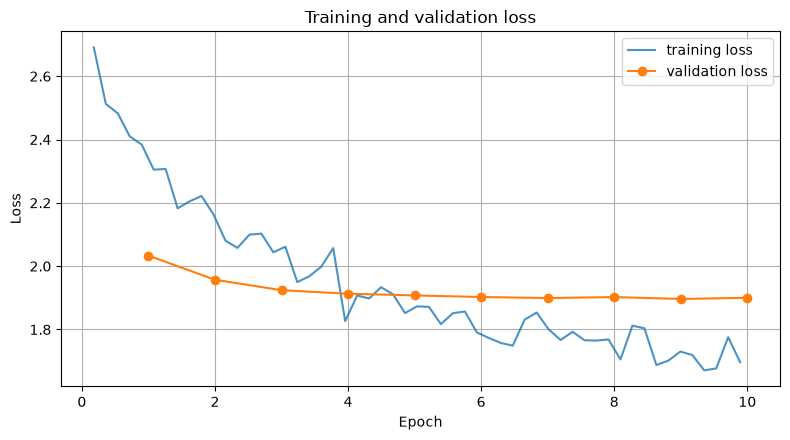

Selected checkpoint: /content/flan-t5-extreme-summary/checkpoint-1251
Best validation loss: 1.896397590637207
Best epoch: 9.0 of 10


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt

log_df = pd.DataFrame(trainer.state.log_history)
log_df.to_csv("/content/training_log.csv", index=False)

train_curve = log_df.dropna(subset=["loss"]) if "loss" in log_df else pd.DataFrame()
eval_curve = log_df.dropna(subset=["eval_loss"]) if "eval_loss" in log_df else pd.DataFrame()

plt.figure(figsize=(8, 4.5))
if len(train_curve):
    plt.plot(train_curve["epoch"], train_curve["loss"], label="training loss", alpha=0.8)
if len(eval_curve):
    plt.plot(eval_curve["epoch"], eval_curve["eval_loss"], marker="o", label="validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and validation loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("Selected checkpoint:", trainer.state.best_model_checkpoint)
print("Best validation loss:", trainer.state.best_metric)
if len(eval_curve):
    best_epoch = float(eval_curve.loc[eval_curve["eval_loss"].idxmin(), "epoch"])
    print("Best epoch:", best_epoch, "of", NUM_EPOCHS)
    if best_epoch >= NUM_EPOCHS:
        print("Validation loss was still improving at the last epoch: consider more epochs or a higher learning rate.")
    elif best_epoch <= 1:
        print("Validation loss was lowest in the first epoch: the model may be overfitting; try a lower learning rate.")

files.download("/content/training_log.csv")

## Step 9 — Save and download the fine-tuned model

The model and tokenizer are saved together so they can be loaded later for inference. Because `load_best_model_at_end=True`, this saves the best checkpoint, not necessarily the last epoch.

In [ ]:
FINAL_MODEL_DIR = "/content/final-finetuned-model"

trainer.save_model(FINAL_MODEL_DIR)
tokenizer.save_pretrained(FINAL_MODEL_DIR)

print("Saved model to:", FINAL_MODEL_DIR)

# Package the model folder as a ZIP for download.
!zip -qr /content/final-finetuned-model.zip /content/final-finetuned-model
files.download("/content/final-finetuned-model.zip")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved model to: /content/final-finetuned-model


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 10 — Load both models for comparison

The baseline must be the original checkpoint, without additional fine-tuning. The fine-tuned model is the best checkpoint selected during training.

In [ ]:
baseline_model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)
baseline_model.eval()

fine_tuned_model = AutoModelForSeq2SeqLM.from_pretrained(FINAL_MODEL_DIR).to(device)
fine_tuned_model.eval()

tokenizer = AutoTokenizer.from_pretrained(FINAL_MODEL_DIR)

print("Baseline and fine-tuned models loaded.")

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Baseline and fine-tuned models loaded.


## Step 11 — Generate summaries

The requested maximum length is given in the prompt. The model is not guaranteed to respect it; whether each summary stays within its cap, and by how much it overshoots, is measured later.

For a fair comparison, both models use the same prompts and the same generation settings (`GEN_KWARGS`). Generation is batched and sorted by length, which is much faster than one example at a time. Outputs are returned in the original order.

In [ ]:
GEN_KWARGS = dict(num_beams=4, do_sample=False)

def generate_summaries(sources, target_lengths, generation_model, batch_size=16):
    prompts = [build_prompt(s, l) for s, l in zip(sources, target_lengths)]
    order = np.argsort([len(p) for p in prompts])[::-1]    # longest first
    outputs = [None] * len(prompts)

    generation_model.eval()
    for start in tqdm(range(0, len(order), batch_size), leave=False):
        idx = order[start:start + batch_size]
        batch = tokenizer(
            [prompts[i] for i in idx],
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=MAX_INPUT_LENGTH
        ).to(device)

        with torch.no_grad():
            output_ids = generation_model.generate(
                **batch,
                max_new_tokens=MAX_TARGET_LENGTH,
                **GEN_KWARGS
            )

        for i, text in zip(idx, tokenizer.batch_decode(output_ids, skip_special_tokens=True)):
            outputs[i] = text.strip()

    return outputs

# Quick sanity check on one test paragraph.
sample_source = test_df.iloc[0]["source"]
sample_lengths = [10, 20, 30]
baseline_sample = generate_summaries([sample_source] * 3, sample_lengths, baseline_model)
finetuned_sample = generate_summaries([sample_source] * 3, sample_lengths, fine_tuned_model)

for pct, base_text, ft_text in zip(sample_lengths, baseline_sample, finetuned_sample):
    print(f"\n--- Requested length: {pct}% ---")
    print("BASELINE:")
    print(base_text)
    print("FINE-TUNED:")
    print(ft_text)

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]


--- Requested length: 10% ---
BASELINE:
A satellite alert system launched in 2021 has helped rangers in the Tamar Forest reduce illegal logging by 43 percent, according to the environment ministry.
FINE-TUNED:
A satellite alert helped rangers reduce illegal logging 43 percent.

--- Requested length: 20% ---
BASELINE:
A satellite alert system launched in 2021 has helped rangers in the Tamar Forest reduce illegal logging by 43 percent, according to the environment ministry.
FINE-TUNED:
A satellite alert system helped rangers reduce illegal logging by 43 percent, reducing logging by 70 percent within 72 hours and confiscating 1,300 cubic meters of wood.

--- Requested length: 30% ---
BASELINE:
A satellite alert system launched in 2021 has helped rangers in the Tamar Forest reduce illegal logging by 43 percent, according to the environment ministry.
FINE-TUNED:
A satellite alert system helped rangers reduce illegal logging by 43 percent, reducing logging by 43 percent, and patrols reach 7

## Step 12 — Generate predictions for the complete test set

This produces six outputs per source paragraph: three length caps for the baseline and three for the fine-tuned model.

The generated results are saved to a CSV file (with `source_id`) for evaluation and manual annotation.

In [ ]:
test_sources = test_df["source"].tolist()
test_lengths = test_df["target_length"].astype(int).tolist()

baseline_predictions = generate_summaries(test_sources, test_lengths, baseline_model)
finetuned_predictions = generate_summaries(test_sources, test_lengths, fine_tuned_model)

predictions_df = pd.DataFrame({
    "source_id": test_df["source_id"].tolist(),
    "source": test_sources,
    "target_length": test_lengths,
    "reference_summary": test_df["target_summary"].tolist(),
    "baseline_summary": baseline_predictions,
    "finetuned_summary": finetuned_predictions
})

predictions_path = "/content/test_predictions.csv"
predictions_df.to_csv(predictions_path, index=False)

display(predictions_df.head(10))
files.download(predictions_path)

  0%|          | 0/8 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

,source_id,source,target_length,reference_summary,baseline_summary,finetuned_summary
0,te_0001,A satellite alert system launched in 2021 has ...,10,Satellite alerts cut illegal logging in Tamar ...,A satellite alert system launched in 2021 has ...,A satellite alert helped rangers reduce illega...
1,te_0001,A satellite alert system launched in 2021 has ...,20,Satellite radar alerts cut illegal logging in ...,A satellite alert system launched in 2021 has ...,A satellite alert system helped rangers reduce...
2,te_0001,A satellite alert system launched in 2021 has ...,30,Satellite radar alerts cut illegal logging in ...,A satellite alert system launched in 2021 has ...,A satellite alert system helped rangers reduce...
3,te_0002,"The Harrowdown stone circle, built about 4,500...",10,Harrowdown stone circle aligns with solstice s...,"The Harrowdown stone circle, built about 4,500...",Harrowdown stone circle consists of 27 stones.
4,te_0002,"The Harrowdown stone circle, built about 4,500...",20,"The 4,500-year-old Harrowdown stone circle ali...","The Harrowdown stone circle, built about 4,500...","Harrowdown stone circle, built about 4,500 yea..."
5,te_0002,"The Harrowdown stone circle, built about 4,500...",30,"The 4,500-year-old Harrowdown stone circle, 27...","The Harrowdown stone circle, built about 4,500...","Harrowdown stone circle, built about 4,500 yea..."
6,te_0003,Hospitals often serve unappetizing meals that ...,10,Kingsmead hospital's room-service meals raised...,Hospitals often serve unappetizing meals that ...,Kingsmead General Hospital introduced a room-s...
7,te_0003,Hospitals often serve unappetizing meals that ...,20,Kingsmead General's room-service meals made pa...,Hospitals often serve unappetizing meals that ...,Kingsmead General Hospital introduced a room-s...
8,te_0003,Hospitals often serve unappetizing meals that ...,30,Kingsmead General's room-service system let pa...,Hospitals often serve unappetizing meals that ...,Kingsmead General Hospital's room-service syst...
9,te_0004,Consumers lose billions of dollars each year t...,10,New rules require subscription cancellation to...,Consumers lose billions of dollars each year t...,Consumers lose billions of dollars each year t...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 13 — Compression ratio, ROUGE-L, and paired bootstrap

Compression ratio is calculated from word counts. Because the requested length is a **maximum**, three measures describe length behavior:

- **Actual compression ratio:** generated words as a percentage of source words.
- **Within-target rate:** the share of summaries at or below their cap (allowing `CEILING_SLACK_PP`).
- **Mean overshoot:** how many percentage points a summary goes above its cap (0 when within it).

A model that ignores the cap can score well on fact coverage simply by writing longer summaries; these measures expose that. ROUGE-L F1 compares each generated summary with the corresponding human-written reference.

ROUGE-L measures textual overlap, not factual correctness. Fact coverage and factual consistency are annotated separately in the next steps.

The tables report the **mean and standard deviation** for each model and length. The paired bootstrap then compares the two models on the *same* source paragraphs: it resamples source paragraphs 10,000 times and reports the 95% confidence interval for the difference (fine-tuned minus baseline). If the interval includes 0, the data do not show a reliable difference. With about 100 test sources, a single run can otherwise mistake noise for improvement.

In [ ]:
from rouge_score import rouge_scorer

rouge = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)

metric_rows = []
for row in predictions_df.itertuples(index=False):
    for model_name, generated in [
        ("baseline", row.baseline_summary),
        ("fine_tuned", row.finetuned_summary)
    ]:
        ratio = compression_ratio(row.source, generated)
        metric_rows.append({
            "source_id": row.source_id,
            "model": model_name,
            "target_length": row.target_length,
            "source_words": word_count(row.source),
            "summary_words": word_count(generated),
            "compression_ratio_percent": ratio,
            "within_target_percent": 100.0 * (ratio <= row.target_length + CEILING_SLACK_PP),
            "overshoot_pp": max(0.0, ratio - row.target_length),
            "rougeL_f1": rouge.score(row.reference_summary, generated)["rougeL"].fmeasure
        })

metrics_df = pd.DataFrame(metric_rows)

summary_metrics = metrics_df.groupby(["model", "target_length"]).agg(
    actual_compression_percent=("compression_ratio_percent", "mean"),
    actual_compression_std=("compression_ratio_percent", "std"),
    within_target_percent=("within_target_percent", "mean"),
    mean_overshoot_pp=("overshoot_pp", "mean"),
    rougeL_f1=("rougeL_f1", "mean"),
    rougeL_f1_std=("rougeL_f1", "std")
).reset_index()

print("Model results (mean and std over test rows):")
display(summary_metrics.round(3))

print("\nFor reference, compression ratio of the human reference summaries in the test set (they only need to be at or below the cap):")
display(test_df.groupby("target_length")["ref_ratio"].agg(["mean", "std"]).round(2))


# ---------- Paired bootstrap helpers (reused in Step 16) ----------
def paired_bootstrap_ci(diffs, n_boot=10000, seed=SEED):
    rng = np.random.default_rng(seed)
    diffs = np.asarray(diffs, dtype=float)
    idx = rng.integers(0, len(diffs), size=(n_boot, len(diffs)))
    boot_means = diffs[idx].mean(axis=1)
    low, high = np.percentile(boot_means, [2.5, 97.5])
    return diffs.mean(), low, high

def paired_comparison(df, value_col, label):
    rows = []
    for length, group in df.groupby("target_length"):
        wide = group.pivot(index="source_id", columns="model", values=value_col).dropna()
        diffs = (wide["fine_tuned"] - wide["baseline"]).to_numpy()
        mean_diff, low, high = paired_bootstrap_ci(diffs)
        rows.append({
            "metric": label,
            "target_length": length,
            "n_sources": len(diffs),
            "mean_diff_ft_minus_base": mean_diff,
            "ci95_low": low,
            "ci95_high": high,
            "ci_excludes_0": bool(low > 0 or high < 0)
        })
    return pd.DataFrame(rows)

rouge_paired = paired_comparison(metrics_df, "rougeL_f1", "ROUGE-L F1")
print("\nPaired bootstrap, ROUGE-L F1 (fine-tuned minus baseline):")
display(rouge_paired.round(4))

Model results (mean and std over test rows):


,model,target_length,actual_compression_percent,actual_compression_std,within_target_percent,mean_overshoot_pp,rougeL_f1,rougeL_f1_std
0,baseline,10,37.016,22.461,2.5,27.081,0.222,0.127
1,baseline,20,43.269,24.394,25.0,23.718,0.253,0.099
2,baseline,30,35.584,23.551,70.0,11.833,0.235,0.096
3,fine_tuned,10,7.245,2.504,92.5,0.306,0.384,0.174
4,fine_tuned,20,18.995,6.009,70.0,1.895,0.357,0.145
5,fine_tuned,30,28.987,9.096,62.5,3.161,0.367,0.128



For reference, compression ratio of the human reference summaries in the test set (they only need to be at or below the cap):


,mean,std
target_length,,
10,7.60,1.05
20,16.61,1.35
30,26.06,1.42



Paired bootstrap, ROUGE-L F1 (fine-tuned minus baseline):


,metric,target_length,n_sources,mean_diff_ft_minus_base,ci95_low,ci95_high,ci_excludes_0
0,ROUGE-L F1,10,40,0.1619,0.1123,0.2118,True
1,ROUGE-L F1,20,40,0.1037,0.0679,0.1405,True
2,ROUGE-L F1,30,40,0.1324,0.0926,0.1733,True


## Step 14 — Create the blind annotation sheet

Fact coverage and factual consistency require human review. To avoid bias toward whichever model you expect to win, the annotation sheet is **blinded**:

- The sheet **does not say which model wrote each summary**. For each source and length, the two outputs appear next to each other in random order.
- A separate **key file** (`annotation_key.csv`) maps each `annotation_id` back to the model. **Do not open the key until annotation is finished.**

Fill in these columns in `annotation_sheet_blind.csv`:

- `total_important_facts`: number of predefined important facts for that **source**. Define the fact list for each source **before reviewing any model output**, and enter the **same number on every row of that source** (the notebook checks this).
- `facts_preserved`: number of those facts accurately preserved in the generated summary.
- `no_factual_errors`: `1` if the summary contains no factual errors; otherwise `0`.

In [ ]:
long_rows = []
for row in predictions_df.itertuples(index=False):
    for model_name, generated in [
        ("baseline", row.baseline_summary),
        ("fine_tuned", row.finetuned_summary)
    ]:
        long_rows.append({
            "source_id": row.source_id,
            "model": model_name,
            "target_length": row.target_length,
            "source": row.source,
            "generated_summary": generated
        })

long_df = pd.DataFrame(long_rows)

# Group by source and length; randomize which model appears first within each pair.
rng = np.random.default_rng(SEED)
long_df["_order"] = rng.random(len(long_df))
long_df = (
    long_df.sort_values(["source_id", "target_length", "_order"])
    .drop(columns="_order")
    .reset_index(drop=True)
)
long_df["annotation_id"] = [f"A{i + 1:04d}" for i in range(len(long_df))]

key_df = long_df[["annotation_id", "model", "source_id", "target_length"]]
blind_df = long_df[["annotation_id", "source_id", "target_length", "source", "generated_summary"]].copy()
blind_df["total_important_facts"] = ""
blind_df["facts_preserved"] = ""
blind_df["no_factual_errors"] = ""

blind_df.to_csv("/content/annotation_sheet_blind.csv", index=False)
key_df.to_csv("/content/annotation_key.csv", index=False)

display(blind_df.head())
files.download("/content/annotation_sheet_blind.csv")
files.download("/content/annotation_key.csv")

,annotation_id,source_id,target_length,source,generated_summary,total_important_facts,facts_preserved,no_factual_errors
0,A0001,te_0001,10,A satellite alert system launched in 2021 has ...,A satellite alert helped rangers reduce illega...,,,
1,A0002,te_0001,10,A satellite alert system launched in 2021 has ...,A satellite alert system launched in 2021 has ...,,,
2,A0003,te_0001,20,A satellite alert system launched in 2021 has ...,A satellite alert system helped rangers reduce...,,,
3,A0004,te_0001,20,A satellite alert system launched in 2021 has ...,A satellite alert system launched in 2021 has ...,,,
4,A0005,te_0001,30,A satellite alert system launched in 2021 has ...,A satellite alert system launched in 2021 has ...,,,


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 15 — Calculate fact coverage and consistency rate

After completing `annotation_sheet_blind.csv`, upload it below. If this Colab session is still running, the key file is read from `/content/annotation_key.csv`; if the runtime was restarted, upload `annotation_key.csv` together with the completed sheet (any file with "key" in its name is treated as the key).

The cell checks that every annotation row is complete, values are in range, and the fact count is **identical for every row of the same source**.

In [ ]:
annotation_upload = files.upload()

csv_names = [name for name in annotation_upload if name.lower().endswith(".csv")]
key_names = [name for name in csv_names if "key" in name.lower()]
sheet_names = [name for name in csv_names if name not in key_names]

if len(sheet_names) != 1:
    raise FileNotFoundError("Upload exactly one completed annotation sheet CSV (plus the key CSV if the runtime restarted).")

key_path = key_names[0] if key_names else "/content/annotation_key.csv"
if not os.path.exists(key_path):
    raise FileNotFoundError("Key file not found. Upload annotation_key.csv together with the completed sheet.")

sheet_df = pd.read_csv(sheet_names[0])
key_df = pd.read_csv(key_path)

human_cols = ["total_important_facts", "facts_preserved", "no_factual_errors"]
missing_cols = {"annotation_id", *human_cols} - set(sheet_df.columns)
if missing_cols:
    raise ValueError(f"Annotation sheet is missing columns: {missing_cols}")

if sheet_df["annotation_id"].duplicated().any():
    raise ValueError("Duplicate annotation_id values in the annotation sheet.")
if set(sheet_df["annotation_id"]) != set(key_df["annotation_id"]):
    raise ValueError(
        "annotation_id values in the sheet do not match the key file "
        f"({len(sheet_df)} sheet rows vs {len(key_df)} key rows)."
    )

for col in human_cols:
    sheet_df[col] = pd.to_numeric(sheet_df[col], errors="coerce")

incomplete = sheet_df[sheet_df[human_cols].isna().any(axis=1)]
if len(incomplete):
    raise ValueError(
        f"{len(incomplete)} rows have blank or non-numeric annotation fields, "
        f"e.g. {incomplete['annotation_id'].head(5).tolist()}."
    )

if (sheet_df["total_important_facts"] <= 0).any():
    raise ValueError("total_important_facts must be greater than zero.")

if ((sheet_df["facts_preserved"] < 0) |
        (sheet_df["facts_preserved"] > sheet_df["total_important_facts"])).any():
    raise ValueError("facts_preserved must be between zero and total_important_facts.")

if not sheet_df["no_factual_errors"].isin([0, 1]).all():
    raise ValueError("no_factual_errors must contain only 0 or 1.")

# Re-attach the model labels and check the fact list is the same for every row of a source.
annotations_df = sheet_df[["annotation_id", *human_cols]].merge(
    key_df, on="annotation_id", how="inner", validate="one_to_one"
)

facts_per_source = annotations_df.groupby("source_id")["total_important_facts"].nunique()
inconsistent = facts_per_source[facts_per_source > 1]
if len(inconsistent):
    raise ValueError(
        f"total_important_facts differs between rows of the same source for {len(inconsistent)} sources, "
        f"e.g. {inconsistent.index[:5].tolist()}. Use one fact list per source for both models."
    )

annotations_df["fact_coverage_percent"] = (
    100 * annotations_df["facts_preserved"] / annotations_df["total_important_facts"]
)
annotations_df["consistency_rate_percent"] = 100 * annotations_df["no_factual_errors"]

human_metrics = annotations_df.groupby(["model", "target_length"]).agg(
    fact_coverage_percent=("fact_coverage_percent", "mean"),
    consistency_rate_percent=("consistency_rate_percent", "mean")
).reset_index()

display(human_metrics.round(3))

KeyboardInterrupt: 

## Step 16 — Combine the four evaluation metrics

The final table reports the four metrics for each model and requested maximum length, with standard deviations for the two automatic metrics, plus the within-target rate and mean overshoot.

- Compression ratio: actual average percentage of source words.
- Within-target rate: percentage of summaries at or below their cap; mean overshoot: average percentage points above the cap.
- ROUGE-L F1: average overlap with the human reference.
- Fact coverage: average percentage of predefined facts preserved.
- Consistency rate: percentage of summaries with no factual errors.

The second table gives the **paired bootstrap comparison** (fine-tuned minus baseline) for all four metrics. `ci_excludes_0 = True` means the 95% interval does not include zero, so the difference is unlikely to be sampling noise. Compression ratio, within-target rate, and overshoot are included because a model that "improves" fact coverage only by writing longer summaries, or by exceeding the cap, has not really improved.

In [ ]:
final_results = summary_metrics.merge(
    human_metrics,
    on=["model", "target_length"],
    how="left"
)

final_results = final_results[
    [
        "model",
        "target_length",
        "actual_compression_percent",
        "actual_compression_std",
        "within_target_percent",
        "mean_overshoot_pp",
        "rougeL_f1",
        "rougeL_f1_std",
        "fact_coverage_percent",
        "consistency_rate_percent"
    ]
]

print("Final results by model and requested maximum length:")
display(final_results.round(3))
final_results.to_csv("/content/final_evaluation_results.csv", index=False)

paired_df = pd.concat([
    paired_comparison(metrics_df, "rougeL_f1", "ROUGE-L F1"),
    paired_comparison(metrics_df, "compression_ratio_percent", "Actual compression (%)"),
    paired_comparison(metrics_df, "within_target_percent", "Within-target rate (%)"),
    paired_comparison(metrics_df, "overshoot_pp", "Overshoot above cap (pp)"),
    paired_comparison(annotations_df, "fact_coverage_percent", "Fact coverage (%)"),
    paired_comparison(annotations_df, "consistency_rate_percent", "Consistency rate (%)"),
], ignore_index=True)

print("\nPaired bootstrap comparison, fine-tuned minus baseline (95% CI):")
display(paired_df.round(3))
paired_df.to_csv("/content/paired_comparison.csv", index=False)

files.download("/content/final_evaluation_results.csv")
files.download("/content/paired_comparison.csv")

## Step 17 — Plot fact coverage against actual compression ratio

This is the primary analysis proposed for the research: compare information preservation at different actual compression levels for the baseline and fine-tuned models. Each point is labeled with its requested maximum length. Because summaries only need to stay at or below the cap, actual compression can differ between models; compare fact coverage at similar actual compression, not just at the same cap.

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for model_name, group in final_results.groupby("model"):
    group = group.sort_values("actual_compression_percent")
    plt.plot(
        group["actual_compression_percent"],
        group["fact_coverage_percent"],
        marker="o",
        label=model_name
    )
    for _, r in group.iterrows():
        plt.annotate(
            f"{int(r['target_length'])}%",
            (r["actual_compression_percent"], r["fact_coverage_percent"]),
            textcoords="offset points", xytext=(5, 5), fontsize=8
        )

plt.xlabel("Actual compression ratio (%)")
plt.ylabel("Fact coverage (%)")
plt.title("Fact Coverage vs. Actual Compression Ratio")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Step 18 — Save your experiment outputs

Download and retain:
- `dataset_checks_report.csv` (pre-training check results)
- `final-finetuned-model.zip`
- `training_log.csv`
- `test_predictions.csv`
- `annotation_sheet_blind.csv` (completed) and `annotation_key.csv`
- `final_evaluation_results.csv`
- `paired_comparison.csv`

## Interpretation and reporting

Use the results to answer:

**Does fine-tuning improve a pretrained Transformer's ability to preserve important facts when summarizing text to only 10%, 20%, or 30% of its original length?**

Compare the baseline and fine-tuned model at each length cap. Do not claim improvement based on ROUGE-L alone. Examine fact coverage and factual consistency alongside actual compression ratio, and use the paired bootstrap intervals: only describe a difference as an improvement when its interval excludes zero.

## Methodology details to report

- Dataset checks performed before training (leakage, duplicates, reference-ratio check) and any warnings that remained.
- Any text normalization applied to make the data representable by the tokenizer (for example `₱` rewritten as `PHP`), applied identically to all splits.
- Token limits used, and the fraction of data they truncated.
- Learning rate, epochs, batch size, precision (fp32 or bf16), and the epoch selected by validation loss.
- Annotation was blinded to model identity, with one fact list per source shared by both models.

## Experimental limitations to report

1. FLAN-T5-small is already instruction-tuned; the experiment measures the effect of additional task-specific fine-tuning.
2. The requested length is a maximum, not an exact target. A model may exceed the cap or use only a small part of it; the within-target rate, overshoot, and actual compression ratio are reported for this reason. Fact coverage naturally rises with summary length, so differences should be read together with actual compression.
3. ROUGE-L measures lexical sequence overlap and does not establish factual correctness.
4. Fact coverage and factual consistency depend on the quality and consistency of human annotations. A single annotator gives no measure of agreement; a second annotator on a subset would let you report it.
5. The dataset is relatively small. Results are from a single training run with one seed; the bootstrap captures test-sample variation but not training-run variation.
6. The bootstrap treats test source paragraphs as independent samples.